# One tensor or two: permeability as second-order spatial dispersion

At optical frequencies no natural material has a magnetic permeability worth the name, yet metamaterials are routinely described by one. Landau and Lifshitz give the reason the first statement is not an accident: at high frequencies the split of the induced current into "electric" and "magnetic" parts is a convention, and everything can be put into one dielectric tensor that depends on the wavevector, $\varepsilon_{ij}(\omega,\mathbf k)$. In that description a permeability is a particular piece of the terms of second order in $\mathbf k$. This notebook works out what "a particular piece" means, exactly and by symmetry, and what the wavevector-dependent tensor does *not* contain. Notebooks 02 to 04 then compute all of it for a lattice of dielectric rods.

## What this notebook shows

- The exact map from local constitutive relations ($\varepsilon$, $\mu$ and magnetoelectric couplings) to a single nonlocal tensor $\varepsilon(\omega,\mathbf k)$, checked on random media: zeroth order in $\mathbf k$ is the permittivity, first order is gyrotropy, second order contains the permeability.
- Free waves in the bulk measure only the refractive index. Every split of $n^2$ into $\varepsilon\mu$ gives the same nonlocal permittivity on the dispersion curve; the split is fixed by information off that curve, or by an interface.
- A count, by group averaging, of how many second-order coefficients a symmetry allows and how many of them a permeability can account for. For a square lattice with $\mathbf E$ in the plane there are three, one of them magnetic; with $\mathbf E$ along the axis there is one, and it is always magnetic.
- The Landau-Lifshitz criterion for a meaningful magnetization, restated as an inequality between second-order coefficients. The magnetic-dipole moment of a unit cell is not the second-order coefficient: quadrupole-order terms enter at the same order, and for a weak rod polarized along its axis they cancel the magnetic dipole exactly.
- Reflection is not determined by the bulk tensor. Three operators with the same symbol reflect differently, and a periodic dielectric stack has a "permeability" below or above one depending on where it is cut.

## Conventions

Time dependence $e^{-i\omega t}$, fields $\propto e^{i\mathbf k\cdot\mathbf r}$, units $\varepsilon_0=\mu_0=c=1$, so $k_0=\omega$. $K$ denotes the matrix of the cross product, $K\mathbf v=\mathbf k\times\mathbf v$, with $K^{\mathsf T}=-K$. "LL" labels the Landau-Lifshitz bookkeeping with a single tensor. The polarization with $\mathbf E$ along $z$ is called TM and the one with $\mathbf H$ along $z$ TE, as in `docs/DESIGN.md`. References are listed at the end; the folder README says which of them were checked against publisher or arXiv records and which are cited from memory.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/spatial_dispersion (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))          # rodlattice.py sits next to this notebook
import rodlattice as rl
from scipy.linalg import null_space

rng = np.random.default_rng(1)

## 1. Two ways to book the induced current

Maxwell's equations in matter contain one material quantity, the induced current $\mathbf j(\omega,\mathbf k)$, linear in the field. There are two common ways to write it.

**Two tensors (and couplings).** Split $\mathbf j=-i\omega\mathbf P+i\mathbf k\times\mathbf M$ and define $\mathbf D=\mathbf E+\mathbf P$, $\mathbf H=\mathbf B-\mathbf M$, with local relations $\mathbf D=\varepsilon\mathbf E+\xi\mathbf H$, $\mathbf B=\zeta\mathbf E+\mu\mathbf H$.

**One tensor (LL).** Put all of the current into the displacement, $\mathbf D_{\rm LL}=\mathbf E+(i/\omega)\,\mathbf j$, and keep $\mathbf H_{\rm LL}=\mathbf B$. The only material tensor is $\varepsilon_{\rm LL}(\omega,\mathbf k)$.

Both must give the same $\mathbf E$ and $\mathbf B$. Subtracting the two forms of Ampère's law, $\mathbf k\times\mathbf H=-k_0\mathbf D$ and $\mathbf k\times\mathbf B=-k_0\mathbf D_{\rm LL}$, gives $\mathbf D_{\rm LL}=\mathbf D-K\mathbf M/k_0$. With Faraday's law $\mathbf B=K\mathbf E/k_0$ and $\mathbf H=\mu^{-1}(\mathbf B-\zeta\mathbf E)$,

$$\varepsilon_{\rm LL}(\omega,\mathbf k)=\underbrace{\varepsilon-\xi\mu^{-1}\zeta}_{k^0}\;+\;\underbrace{\frac{\xi\mu^{-1}K-K\mu^{-1}\zeta}{k_0}}_{k^1:\ \text{gyrotropy}}\;+\;\underbrace{\frac{K^{\mathsf T}(1-\mu^{-1})K}{k_0^2}}_{k^2:\ \text{magnetism}} .$$

For an isotropic medium without magnetoelectric coupling $K^{\mathsf T}K=k^2-\mathbf k\mathbf k^{\mathsf T}$, so the longitudinal part is untouched and the transverse part is

$$\varepsilon^{T}_{\rm LL}(\omega,k)=\varepsilon(\omega)+\frac{k^2}{k_0^2}\Big(1-\frac1{\mu(\omega)}\Big),\qquad\varepsilon^{L}_{\rm LL}=\varepsilon(\omega),$$

which is the relation in Landau and Lifshitz, section 103. The map is exact, not an expansion: a local permeability is a nonlocal permittivity whose $\mathbf k$ dependence stops at second order and has the tensor form $K^{\mathsf T}(\cdot)K$.

The next cell checks the identity on random complex media in two ways. (a) For arbitrary $\mathbf E$ and complex $\mathbf k$, off any dispersion relation, the residual of Ampère's law is the same in both schemes, so the two respond identically to any external current. (b) The four refractive indices along a random direction, from the $6\times6$ eigenproblem of the two-tensor scheme, are roots of the LL determinant.

In [3]:
def cross_matrix(k):
    return np.array([[0, -k[2], k[1]], [k[2], 0, -k[0]], [-k[1], k[0], 0]])


def eps_LL(eps, mu, xi, zeta, k, k0=1.0):
    """Landau-Lifshitz permittivity equivalent to D = eps E + xi H, B = zeta E + mu H."""
    K, mi = cross_matrix(k), np.linalg.inv(mu)
    return eps - xi @ mi @ zeta + (xi @ mi @ K - K @ mi @ zeta) / k0 - K @ (np.eye(3) - mi) @ K / k0**2


def random_medium(coupling=0.3):
    c = lambda s: s * (rng.normal(size=(3, 3)) + 1j * rng.normal(size=(3, 3)))
    return 2.0 * np.eye(3) + c(0.5), 1.5 * np.eye(3) + c(0.5), c(coupling), c(coupling)


worst_a, worst_b = 0.0, 0.0
for trial in range(200):
    eps, mu, xi, zeta = random_medium()
    # (a) same Ampere residual for arbitrary E and complex k
    k = rng.normal(size=3) + 1j * rng.normal(size=3)
    E = rng.normal(size=3) + 1j * rng.normal(size=3)
    K = cross_matrix(k)
    B = K @ E
    H = np.linalg.solve(mu, B - zeta @ E)
    D = eps @ E + xi @ H
    res_two = K @ H + D                                 # k x H + k0 D, with k0 = 1
    res_LL = K @ B + eps_LL(eps, mu, xi, zeta, k) @ E   # k x B + k0 D_LL
    worst_a = max(worst_a, np.abs(res_two - res_LL).max() / np.abs(res_two).max())
    # (b) indices along a real direction: [[zeta, mu], [eps, xi]] v = n diag(Kh, -Kh) v, v = (E, H)
    kh = rng.normal(size=3); kh /= np.linalg.norm(kh)
    Kh = cross_matrix(kh)
    C = np.block([[zeta, mu], [eps, xi]])
    J = np.block([[Kh, np.zeros((3, 3))], [np.zeros((3, 3)), -Kh]])
    lam = np.linalg.eigvals(np.linalg.solve(C, J))
    n_modes = 1 / lam[np.argsort(-np.abs(lam))[:4]]     # two eigenvalues vanish (no longitudinal propagation)
    for n in n_modes:
        sv = np.linalg.svd(n**2 * Kh @ Kh + eps_LL(eps, mu, xi, zeta, n * kh), compute_uv=False)
        worst_b = max(worst_b, sv[-1] / sv[0])
check("(a) Ampere residuals agree off shell, 200 random media (relative)", worst_a, 1e-12)
check("(b) indices of the two-tensor scheme annihilate the LL wave operator (smallest/largest singular value)", worst_b, 1e-10)

PASS  (a) Ampere residuals agree off shell, 200 random media (relative): got 6.53891e-16, target 0, |diff| 6.54e-16 <= 1e-12
PASS  (b) indices of the two-tensor scheme annihilate the LL wave operator (smallest/largest singular value): got 3.22349e-15, target 0, |diff| 3.22e-15 <= 1e-10


## 2. Bulk waves fix the index, not the split

Take the isotropic case. A transverse wave obeys $k^2=k_0^2\,\varepsilon^T_{\rm LL}(\omega,k)$, and with the expression above this is $k^2=k_0^2\varepsilon\mu$. On that curve

$$\varepsilon^T_{\rm LL}\big(\omega,k=nk_0\big)=\varepsilon+\varepsilon\mu\Big(1-\frac1\mu\Big)=\varepsilon\mu=n^2 .$$

So every pair $(\varepsilon',\mu')$ with $\varepsilon'\mu'=n^2$ has the same LL permittivity where free waves live. As functions of $k$ at fixed frequency they are different straight lines in $k^2$ that cross at one point. A measurement confined to that point, the propagation of bulk waves, returns $n(\omega)$ and nothing about the split. The split needs one of two things:

1. **Off-shell information**: the response to a source with a wavevector that is not $nk_0$, in particular the slope $\partial\varepsilon_{\rm LL}/\partial k^2$ at $k=0$. Notebook 03 computes it for a real structure by driving the lattice with an external current.
2. **An interface**, where the impedance enters. Notebook 04 does that with an exact slab solver.

There is no theorem that the two agree, and section 5 below gives the elementary reason they need not.

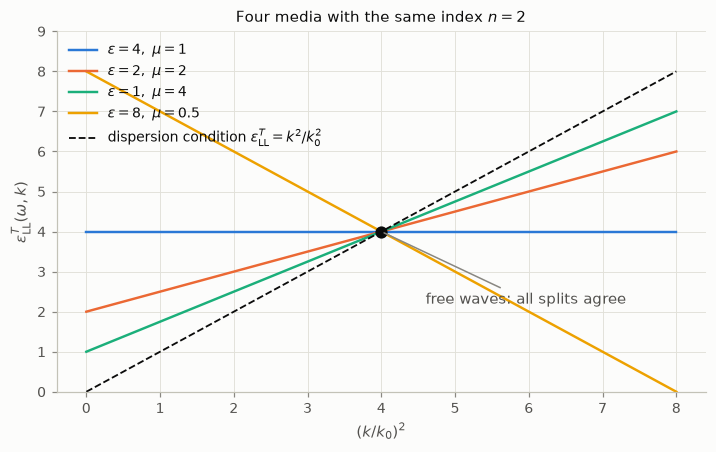

PASS  all splits give eps_LL = n^2 on shell (max deviation): got 0, target 0, |diff| 0.00e+00 <= 1e-14


In [4]:
n2 = 4.0
splits = [(4.0, 1.0), (2.0, 2.0), (1.0, 4.0), (8.0, 0.5)]
x = np.linspace(0, 8, 200)                    # (k / k0)^2
fig, ax = plt.subplots()
for (e, m), col in zip(splits, CAT):
    ax.plot(x, e + x * (1 - 1 / m), color=col, label=rf"$\varepsilon={e:g},\ \mu={m:g}$")
ax.plot(x, x, color=INK, ls="--", lw=1.2, label=r"dispersion condition $\varepsilon^T_{\rm LL}=k^2/k_0^2$")
ax.plot([n2], [n2], "o", color=INK, ms=7)
ax.annotate("free waves: all splits agree", (n2, n2), (4.6, 2.2), color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set(xlabel=r"$(k/k_0)^2$", ylabel=r"$\varepsilon^T_{\rm LL}(\omega,k)$", title=r"Four media with the same index $n=2$", ylim=(0, 9))
ax.legend(loc="upper left")
plt.show()
check("all splits give eps_LL = n^2 on shell (max deviation)", max(abs(e + n2 * (1 - 1 / m) - n2) for e, m in splits), 1e-14)

## 3. Which second-order terms can be a permeability?

Expand a general nonlocal tensor to second order,

$$\varepsilon_{ij}(\omega,\mathbf k)=\varepsilon_{ij}+\gamma_{ijl}k_l+\alpha_{ijlm}k_lk_m+\dots$$

In a reciprocal medium $\varepsilon_{ij}(\omega,\mathbf k)=\varepsilon_{ji}(\omega,-\mathbf k)$, so $\alpha$ is symmetric in $ij$ as well as in $lm$: it lives in $\mathrm{Sym}^2\otimes\mathrm{Sym}^2$, which has 36 components in three dimensions (the index symmetry of an elastic tensor without the major symmetry). A permeability contributes $\alpha^{\rm mag}k k=K^{\mathsf T}\chi K/k_0^2$ with $\chi=1-\mu^{-1}$ symmetric, a 6-dimensional subspace. A point group $G$ leaves only its invariants, whose number is the trace of the Reynolds projector $\tfrac1{|G|}\sum_g S(g)\otimes S(g)$, with $S$ the representation on symmetric matrices. For the continuous groups the invariants are the common null space of the generators.

In two dimensions with $\mathbf k$ in the plane the tensor splits into two blocks. For $\mathbf E$ in the plane (TE), $\alpha_{ijlm}$ has all indices in the plane, 9 components, and the only magnetic one is $\mu_{zz}$. For $\mathbf E$ along $z$ (TM), $\alpha_{zzlm}$ is a symmetric $2\times2$ matrix in $lm$, and the magnetic term is $(k_y,-k_x)\,\chi\,(k_y,-k_x)^{\mathsf T}$ with $\chi$ the in-plane part of $1-\mu^{-1}$: an arbitrary quadratic form in $\mathbf k$.

In [5]:
def sym_basis(d):
    """Orthonormal basis of the symmetric d x d matrices."""
    B = []
    for i in range(d):
        for j in range(i, d):
            m = np.zeros((d, d)); m[i, j] = m[j, i] = 1.0
            B.append(m / np.linalg.norm(m))
    return np.array(B)


def sym_rep(g, B):
    """Matrix of S -> g S g^T on symmetric matrices in the basis B."""
    return np.einsum("aij,bij->ab", B, np.einsum("ik,bkl,jl->bij", g, B, g))


def reynolds(group, B):
    return np.mean([np.kron(sym_rep(g, B), sym_rep(g, B)) for g in group], axis=0)


def lie_invariants(generators, B):
    """Null space of the generators acting on Sym2 (x) Sym2 (columns are invariant tensors)."""
    s = len(B)
    rows = []
    for Lg in generators:
        dS = np.einsum("aij,bij->ab", B, np.einsum("ik,bkj->bij", Lg, B) + np.einsum("bik,jk->bij", B, Lg))
        rows.append(np.kron(dS, np.eye(s)) + np.kron(np.eye(s), dS))
    return null_space(np.vstack(rows))


def alpha_from_quadratic(Q, B, d):
    """Coordinates in Sym2 (x) Sym2 of alpha defined by Q_ij(k) = alpha_ijlm k_l k_m (polarization identity)."""
    e = np.eye(d)
    alpha = np.zeros((d, d, d, d))
    for l in range(d):
        for m in range(d):
            alpha[:, :, l, m] = 0.5 * (Q(e[l] + e[m]) - Q(e[l]) - Q(e[m]))
    return np.einsum("ijlm,aij,blm->ab", alpha, B, B).ravel()


def magnetic_vectors_3d(B3):
    out = []
    for chi in sym_basis(3):
        Q = lambda k, chi=chi: cross_matrix(k).T @ chi @ cross_matrix(k)
        out.append(alpha_from_quadratic(Q, B3, 3))
    return np.array(out).T


rank = lambda A: np.linalg.matrix_rank(A, tol=1e-9)

# --- three dimensions
B3 = sym_basis(3)
from itertools import permutations, product
Oh = [np.array([[s[i] * (p[i] == j) for j in range(3)] for i in range(3)], float) for p in permutations(range(3)) for s in product((1, -1), repeat=3)]
so3 = [cross_matrix(e) for e in np.eye(3)]
mag3 = magnetic_vectors_3d(B3)
P_Oh = reynolds(Oh, B3)
inv_O3 = lie_invariants(so3, B3)
P_O3 = inv_O3 @ inv_O3.T
rows = [("3D, no symmetry", 36, rank(mag3)),
        ("3D, cubic O_h", round(np.trace(P_Oh)), rank(P_Oh @ mag3)),
        ("3D, isotropic O(3)", inv_O3.shape[1], rank(P_O3 @ mag3))]

# --- two dimensions, E in the plane (TE block)
B2 = sym_basis(2)
rot = lambda t: np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
mirror = np.diag([1.0, -1.0])
C4v = [rot(j * np.pi / 2) @ m for j in range(4) for m in (np.eye(2), mirror)]
mag2 = alpha_from_quadratic(lambda k: (k @ k) * np.eye(2) - np.outer(k, k), B2, 2)[:, None]   # mu_zz
P_C4v = reynolds(C4v, B2)
inv_SO2 = lie_invariants([np.array([[0.0, -1.0], [1.0, 0.0]])], B2)
P_O2 = 0.5 * (np.eye(9) + np.kron(sym_rep(mirror, B2), sym_rep(mirror, B2))) @ inv_SO2 @ inv_SO2.T
rows += [("2D, E in plane, no symmetry", 9, rank(mag2)),
         ("2D, E in plane, square C4v", round(np.trace(P_C4v)), rank(P_C4v @ mag2)),
         ("2D, E in plane, isotropic O(2)", rank(P_O2), rank(P_O2 @ mag2))]

# --- two dimensions, E along z (TM block): alpha_zzlm is one symmetric 2 x 2 matrix
magz = np.array([[np.einsum("lm,alm->a", np.array([[c[1, 1], -c[0, 1]], [-c[0, 1], c[0, 0]]]), B2)] for c in B2])[:, 0, :].T
P_z = np.mean([sym_rep(g, B2) for g in C4v], axis=0)
rows += [("2D, E along z, no symmetry", 3, rank(magz)), ("2D, E along z, square C4v", round(np.trace(P_z)), rank(P_z @ magz))]

print(f"{'setting':34s} {'second-order coefficients':>26s} {'of which a permeability':>26s}")
for name, total, mag in rows:
    print(f"{name:34s} {total:26d} {mag:26d}")
expected = [(36, 6), (3, 1), (2, 1), (9, 1), (3, 1), (2, 1), (3, 3), (1, 1)]
check("counts match the expected table (number of mismatches)", sum((t, m) != e for (_, t, m), e in zip(rows, expected)), 0)
check("the magnetic invariant lies inside the cubic invariants (residual)", np.abs(P_Oh @ (P_Oh @ mag3) - P_Oh @ mag3).max(), 1e-12)

setting                             second-order coefficients    of which a permeability
3D, no symmetry                                            36                          6
3D, cubic O_h                                               3                          1
3D, isotropic O(3)                                          2                          1
2D, E in plane, no symmetry                                 9                          1
2D, E in plane, square C4v                                  3                          1
2D, E in plane, isotropic O(2)                              2                          1
2D, E along z, no symmetry                                  3                          3
2D, E along z, square C4v                                   1                          1
PASS  counts match the expected table (number of mismatches): got 0, target 0, |diff| 0.00e+00 <= 0e+00
PASS  the magnetic invariant lies inside the cubic invariants (residual): got 5.55112e-17, targ

Reading the table:

- **Isotropic medium.** Two coefficients: one multiplies $k^2\delta_{ij}-k_ik_j$ and is the permeability, the other multiplies $k_ik_j$ and only moves the longitudinal response. Transverse bulk waves see one function of frequency at this order, and it is a permeability. This is the Landau-Lifshitz statement.
- **Cubic crystal.** One more coefficient, the cubic anisotropy, which no $\varepsilon$ and $\mu$ can represent because both are scalars for a cubic point group. It makes the index depend on the direction of propagation and on polarization. Lorentz predicted it in 1878; it is the intrinsic birefringence measured in silicon and, at 157 nm, in CaF$_2$.
- **Square lattice, $\mathbf E$ in the plane.** The same structure in two dimensions: a permeability $\mu_{zz}$, a longitudinal term, and one anisotropy.
- **$\mathbf E$ along $z$.** Every second-order term has the form of an in-plane permeability tensor, with or without symmetry. With $C_{4v}$ it is one isotropic number. In this polarization "is the $k^2$ term a permeability?" is not a question; what remains open is its size, the higher orders, and the interface.

For the square lattice with $\mathbf E$ in the plane write the three invariants as

$$\alpha_{ijlm}k_lk_m=a\,k^2\delta_{ij}+b\,(k_x^2-k_y^2)(\sigma_z)_{ij}+c\,(2k_xk_y)(\sigma_x)_{ij},$$

and let $\varphi$ be the angle of $\mathbf k$ from a lattice axis. With $\tau=a-\tfrac12(b+c)$, $\lambda=a+\tfrac12(b+c)$ and $\delta=\tfrac12(b-c)$ the components along and across $\mathbf k$ are

$$\text{transverse: }\ \tau-\delta\cos4\varphi,\qquad\text{longitudinal: }\ \lambda+\delta\cos4\varphi,\qquad\text{mixed: }\ -\delta\sin4\varphi .$$

A pure permeability is $\tau=(1-1/\mu_{zz})/k_0^2$ with $\lambda=\delta=0$. So $\tau$ is the magnetic part, $\lambda$ is invisible to transverse waves along the symmetry directions, and $\delta$ is the part that transverse waves see and that no permeability reproduces: an apparent $\mu$ that differs between $\Gamma X$ ($\varphi=0$) and $\Gamma M$ ($\varphi=\pi/4$). The next cell checks the angular formulas on a random invariant tensor. Notebook 03 measures $\tau$, $\lambda$ and $\delta$ for the rod lattice.

In [6]:
A_rand = (P_C4v @ rng.normal(size=9)).reshape(3, 3)                  # a random C4v-invariant alpha, in the basis B2
alpha = np.einsum("ab,aij,blm->ijlm", A_rand, B2, B2)
Qk = lambda phi: np.einsum("ijlm,l,m->ij", alpha, *(2 * [np.array([np.cos(phi), np.sin(phi)])]))
comp = lambda phi: (lambda kh, th, Q: (th @ Q @ th, kh @ Q @ kh, th @ Q @ kh))(
    np.array([np.cos(phi), np.sin(phi)]), np.array([-np.sin(phi), np.cos(phi)]), Qk(phi))
(TX, LX, _), (TM_, LM, _) = comp(0.0), comp(np.pi / 4)
tau, delta, lam = 0.5 * (TX + TM_), 0.5 * (TM_ - TX), 0.5 * (LX + LM)
phis = np.linspace(0, 2 * np.pi, 97)
err = max(np.abs(np.array(comp(p)) - np.array([tau - delta * np.cos(4 * p), lam + delta * np.cos(4 * p), -delta * np.sin(4 * p)])).max() for p in phis)
check("angular dependence tau - delta cos(4 phi), lambda + delta cos(4 phi), -delta sin(4 phi)", err, 1e-12)
check("trace of the k^2 term is isotropic: (T + L) at GX equals (T + L) at GM", (TX + LX) - (TM_ + LM), 1e-12)

PASS  angular dependence tau - delta cos(4 phi), lambda + delta cos(4 phi), -delta sin(4 phi): got 4.44089e-16, target 0, |diff| 4.44e-16 <= 1e-12
PASS  trace of the k^2 term is isotropic: (T + L) at GX equals (T + L) at GM: got 0, target 0, |diff| 0.00e+00 <= 1e-12


## 4. A magnetic dipole is not yet a second-order coefficient

### 4.1 The Landau-Lifshitz criterion

Landau and Lifshitz ask when a magnetization is a meaningful quantity at all (*Electrodynamics of Continuous Media*, section 79 of the second edition, on the dispersion of the permeability). In outline, with factors of order one dropped: the mean current is $\nabla\times\mathbf M+\partial\mathbf P/\partial t$ and only the sum is physical, since a gradient can be moved between the two terms. $\mathbf M$ is the magnetic moment per unit volume only if the first term dominates the moment of the current. In a body of size $l$ much smaller than the wavelength the electric field is of order $(l/\lambda)H$, so the polarization current is of order $\omega\kappa\,(l/\lambda)H$, with $\kappa$ the dielectric susceptibility, against $\chi H/l$ for the magnetization current. The requirement is

$$\chi\gg\kappa\,(l/\lambda)^2 .$$

For natural media at optical frequencies the magnetic susceptibility is itself of order $(d/\lambda)^2$ with $d$ an atomic length, so the inequality fails for every body larger than an atom, and the conclusion is that $\mu$ must be put equal to one there. Their chapter on spatial dispersion (section 103 and after) is the constructive side of the same argument: keep one tensor $\varepsilon(\omega,\mathbf k)$, in which whatever is left of magnetism sits among the terms of second order in $\mathbf k$.

In the language of section 3 the criterion is an inequality between second-order coefficients. The magnetic one is $\chi/k_0^2$. The others come from the same expansion in the phase of the field across the microscopic unit, of size $a$, and are of order $\kappa a^2$. So the magnetization is meaningful when the coefficient $\tau$ of section 3 dominates $\lambda$, $\delta$ and whatever part of $\tau$ itself is not a current loop: $\chi\gg\kappa\,(k_0a)^2$, the inequality above with the body shrunk to one cell.

The way around it, stated by Merlin in 2009 in direct reply to the argument, is that the estimate $\chi\sim(d/\lambda)^2$ assumes inclusions of ordinary permittivity. A loop current driven in an inclusion of permittivity $\varepsilon_r$ grows with $\varepsilon_r-1$, while the competing terms are limited by depolarization. Notebook 03 measures both sides of the inequality for the rod lattice.

### 4.2 Four contributions at second order

The macroscopic polarization that enters $\varepsilon(\omega,\mathbf k)$ is the Fourier component of the microscopic current, $\mathbf P(\mathbf k)=\frac{i}{\omega A}\int_{\rm cell}\mathbf j(\mathbf r)\,e^{-i\mathbf k\cdot\mathbf r}\,d^2r$. Expanding the exponential gives the familiar multipoles of the cell:

$$\int j_i\,e^{-i\mathbf k\cdot\mathbf r}=\underbrace{\int j_i}_{\text{electric dipole}}-ik_l\Big[\underbrace{\tfrac12\!\int(j_ir_l+j_lr_i)}_{\text{electric quadrupole}}+\underbrace{\tfrac12\!\int(j_ir_l-j_lr_i)}_{\text{magnetic dipole}}\Big]-\tfrac12k_lk_m\underbrace{\int j_ir_lr_m}_{\text{second moments}}+\dots$$

The field that drives the cell also varies as $e^{i\mathbf k\cdot\mathbf r}$. At second order in $k$ four things therefore contribute: the magnetic dipole induced by $\mathbf B=\mathbf k\times\mathbf E/\omega$, the electric quadrupole induced by the gradient of $\mathbf E$, the electric dipole induced by the second derivatives of $\mathbf E$, and the second moments of the current induced by the uniform part of $\mathbf E$. Only the first has the name "magnetic". The four are not separately meaningful (moving the origin mixes them), and only the sum is the coefficient of section 3.

**A case where the sum vanishes.** Take a weak dielectric rod of radius $R$, $\varepsilon_r-1\ll1$, with $\mathbf E$ along its axis. In the Born approximation the field inside is the driving field, $\mathbf j=-i\omega(\varepsilon_r-1)E_0e^{i\mathbf k\cdot\mathbf r}\hat z$, and the Fourier component at the same $\mathbf k$ is $(\varepsilon_r-1)E_0\,\pi R^2/A$ exactly: no $k$ dependence at all. Yet the rod has a magnetic-dipole moment and radiates it. The far field of the rod at outgoing wavevector $\mathbf q$ is the Fourier component at $\mathbf q-\mathbf k$, proportional to

$$\frac{2J_1(u)}{u},\quad u=|\mathbf q-\mathbf k|R,\qquad\approx1-\frac{(k_0R)^2}{4}\,(1-\cos\theta).$$

The $\cos\theta$ term is the order $m=\pm1$ partial wave, the magnetic dipole; the angle-independent $-(k_0R)^2/4$ is the correction to the monopole from the second moments. In the forward direction they cancel. In terms of the scattering coefficients $t_m$ of the rod ($t_{-1}=t_1$): $t_0\propto1-(k_0R)^2/4$, $2t_1\propto(k_0R)^2/4$, and the forward amplitude $t_0+2t_1$ has no correction. The cell checks this with the exact coefficients of rods of increasing contrast.

In [7]:
x = 0.2                                              # k0 R
print(" eps_r    t0/lead - 1    2 t1/lead     forward (t0 + 2 t1)/lead - 1    backward (t0 - 2 t1)/lead - 1")
table = {}
for eps_r in (1.001, 1.01, 1.1):
    t = rl.mie_t(np.array([0, 1]), x, 1.0, eps_r, "TM")
    lead = 0.25j * np.pi * (eps_r - 1) * x**2       # thin-rod monopole coefficient
    table[eps_r] = (t[0] / lead - 1, 2 * t[1] / lead, (t[0] + 2 * t[1]) / lead - 1, (t[0] - 2 * t[1]) / lead - 1)
    print(f"{eps_r:6.3f}   " + "   ".join(f"{v.real:+.5f}{v.imag:+.5f}i" for v in table[eps_r]))
print(f"Born prediction:  -x^2/4 = {-x**2/4:+.5f},  +x^2/4 = {x**2/4:+.5f},  0,  -x^2/2 = {-x**2/2:+.5f}")
check("weak rod: monopole correction is -x^2/4", table[1.001][0].real, 2e-4, -x**2 / 4)
check("weak rod: magnetic-dipole term is +x^2/4", table[1.001][1].real, 2e-4, x**2 / 4)
check("weak rod: the two cancel in the forward direction", abs(table[1.001][2]), 2e-4)

 eps_r    t0/lead - 1    2 t1/lead     forward (t0 + 2 t1)/lead - 1    backward (t0 - 2 t1)/lead - 1
 1.001   -0.00991+0.00003i   +0.00993+0.00000i   +0.00002+0.00003i   -0.01985+0.00003i
 1.010   -0.00956+0.00031i   +0.00993+0.00000i   +0.00037+0.00031i   -0.01950+0.00031i
 1.100   -0.00608+0.00310i   +0.00994+0.00000i   +0.00386+0.00310i   -0.01602+0.00310i
Born prediction:  -x^2/4 = -0.01000,  +x^2/4 = +0.01000,  0,  -x^2/2 = -0.02000
PASS  weak rod: monopole correction is -x^2/4: got -0.00991151, target -0.01, |diff| 8.85e-05 <= 2e-04
PASS  weak rod: magnetic-dipole term is +x^2/4: got 0.00993361, target 0.01, |diff| 6.64e-05 <= 2e-04
PASS  weak rod: the two cancel in the forward direction: got 3.79058e-05, target 0, |diff| 3.79e-05 <= 2e-04


For the weak rod the magnetic-dipole radiation is there, one percent of the monopole at this size, and the forward amplitude does not know about it. Since the index of a dilute array is set by forward scattering, the magnetic dipole of such a rod leaves no trace in $n(\omega)$ at this order, and none in $\varepsilon(\omega,\mathbf k)$. As the contrast grows the forward amplitude acquires corrections of first order in $\varepsilon_r-1$, which come from the field inside no longer being the driving field; this table cannot say how much of that is a $k^2$ effect, and notebook 03 answers it for a strong rod in the lattice. The lesson stands: a scheme that assigns the $m=\pm1$ scattering of the rod to a permeability and a scheme that reads the permeability off the $k^2$ coefficient of $\varepsilon(\omega,\mathbf k)$ distribute the same physics differently between $\varepsilon$ and $\mu$. By section 2 they can agree on the index all the same. Notebooks 03 and 04 find three different values of $\mu-1$ for one lattice at low frequency, one from each of these two schemes and one from a slab.

## 5. Interfaces are not in the symbol

### 5.1 Three operators with one symbol

In one dimension with $E$ along $z$ and propagation along $x$, a slab with a permeability obeys $\big(\mu^{-1}E'\big)'+k_0^2\varepsilon E=0$. In the LL language the magnetic response is the nonlocal polarization with symbol $\chi k^2/k_0^2$, $\chi=1-\mu^{-1}$. Once $\chi$ depends on position, the symbol does not say where the derivatives go:

$$\text{(a)}\ \ \big((1-\chi)E'\big)'+k_0^2\varepsilon E=0,\qquad\text{(b)}\ \ (1-\chi)E''+k_0^2\varepsilon E=0,\qquad\text{(c)}\ \ \big((1-\chi)E\big)''+k_0^2\varepsilon E=0 .$$

All three have the bulk dispersion $k^2=k_0^2\varepsilon\mu$. Ordering (a) is the magnetization current $\nabla\times\mathbf M$ with $\mathbf M$ local in $\mathbf B$; it keeps $E$ and $\mu^{-1}E'$ continuous and reflects with the impedance $z=\sqrt{\mu/\varepsilon}$. Ordering (b) is a nonmagnetic medium of permittivity $\varepsilon\mu$: it keeps $E$ and $E'$ continuous and reflects with $1/n$. Ordering (c) is (b) for the variable $(1-\chi)E$ and has the same reflection. The difference between (a) and (b) is the term $-\chi'E'$, a current sheet located where $\chi$ changes: the surface magnetization current.

The cell solves (a) and (b) for a slab whose edges are smooth, with a transition of width $w$ in which $\varepsilon$ and $\chi$ follow the same profile, and compares with the two sharp-interface formulas. The difference is not an artifact of a sharp edge: it is there at any width small compared with the wavelength. In (b) the product $\varepsilon\mu$ is not linear in the profile, so the edge also changes the optical thickness by a fraction of $w$ and shifts the fringes slightly; the peak reflectance does not depend on thickness and is the clean comparison.

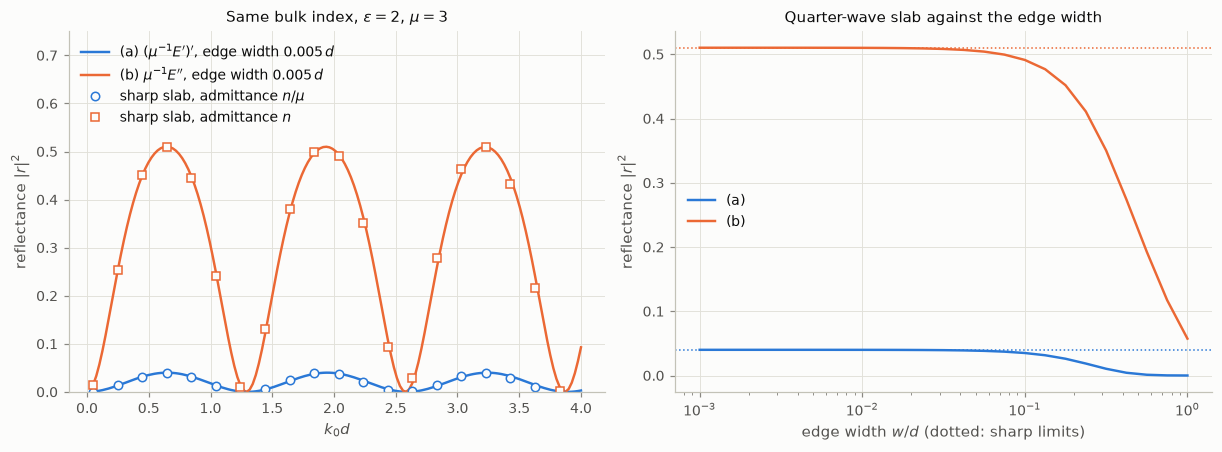

PASS  (a) with a narrow edge reproduces the sharp slab with admittance n/mu (max |R difference|): got 0.00379328, target 0, |diff| 3.79e-03 <= 5e-03
PASS  (a) peak reflectance is that of admittance n/mu: got 0.0399971, target 0.04, |diff| 2.86e-06 <= 5e-03
PASS  (b) peak reflectance is that of admittance n: got 0.510171, target 0.510204, |diff| 3.30e-05 <= 5e-03
(b) against the sharp slab, point by point: max |R difference| = 0.029 (a shift of the fringes, as explained above)


In [8]:
def stack_rt(k0, thickness, eps, mu):
    """(r, t) at normal incidence for layers (left to right) between vacuum half-spaces; E and E'/mu continuous."""
    Mtot = np.eye(2, dtype=complex)
    for d, e, m in zip(thickness, eps, mu):
        n = np.sqrt(complex(e * m)); y = n / m; ph = n * k0 * d
        Mtot = Mtot @ np.array([[np.cos(ph), -1j * np.sin(ph) / y], [-1j * y * np.sin(ph), np.cos(ph)]])
    (A, B), (C, D) = Mtot
    return (A + B - C - D) / (A + B + C + D), 2 / (A + B + C + D)


def smooth_slab(k0, d, eps, mu, w, ordering, nx=4000):
    """Slab of thickness d with tanh edges of width w, discretized in thin layers."""
    L = d + 16 * w
    xs = (np.arange(nx) + 0.5) * L / nx - L / 2
    s = 0.5 * (np.tanh((xs + d / 2) / w) - np.tanh((xs - d / 2) / w))
    e_x = 1 + (eps - 1) * s
    m_x = 1 / (1 - (1 - 1 / mu) * s)                     # chi = 1 - 1/mu follows the profile
    if ordering == "a":
        r, t = stack_rt(k0, np.full(nx, L / nx), e_x, m_x)
    else:                                                # (b): a nonmagnetic medium with permittivity eps * mu
        r, t = stack_rt(k0, np.full(nx, L / nx), e_x * m_x, np.ones(nx))
    return r * np.exp(-1j * k0 * (L - d)), t * np.exp(-1j * k0 * (L - d))   # refer both to the planes x = -d/2, d/2


def sharp_slab(k0, d, n, y):
    r01 = (1 - y) / (1 + y); ph = np.exp(1j * n * k0 * d)
    return r01 * (1 - ph**2) / (1 - r01**2 * ph**2), (1 - r01**2) * ph / (1 - r01**2 * ph**2)


eps_s, mu_s, d = 2.0, 3.0, 1.0
n_s = np.sqrt(eps_s * mu_s)
k0s = np.linspace(0.05, 4.0, 160)
Ra = np.array([abs(smooth_slab(k, d, eps_s, mu_s, 0.005, "a")[0]) ** 2 for k in k0s])
Rb = np.array([abs(smooth_slab(k, d, eps_s, mu_s, 0.005, "b")[0]) ** 2 for k in k0s])
Ra_sharp = np.array([abs(sharp_slab(k, d, n_s, n_s / mu_s)[0]) ** 2 for k in k0s])
Rb_sharp = np.array([abs(sharp_slab(k, d, n_s, n_s)[0]) ** 2 for k in k0s])

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ax = axs[0]
ax.plot(k0s, Ra, color=CAT[0], label=r"(a) $(\mu^{-1}E')'$, edge width $0.005\,d$")
ax.plot(k0s, Rb, color=CAT[1], label=r"(b) $\mu^{-1}E''$, edge width $0.005\,d$")
ax.plot(k0s[::8], Ra_sharp[::8], "o", color=CAT[0], mfc=SURFACE, label=r"sharp slab, admittance $n/\mu$")
ax.plot(k0s[::8], Rb_sharp[::8], "s", color=CAT[1], mfc=SURFACE, label=r"sharp slab, admittance $n$")
ax.set(xlabel=r"$k_0 d$", ylabel=r"reflectance $|r|^2$", title=r"Same bulk index, $\varepsilon=2$, $\mu=3$", ylim=(0, 0.75)); ax.legend(loc="upper left")
ws = np.geomspace(1e-3, 1.0, 25)
kq = np.pi / (2 * n_s * d)                           # quarter-wave slab: maximal reflection
ax = axs[1]
ax.semilogx(ws, [abs(smooth_slab(kq, d, eps_s, mu_s, w, "a")[0]) ** 2 for w in ws], color=CAT[0], label="(a)")
ax.semilogx(ws, [abs(smooth_slab(kq, d, eps_s, mu_s, w, "b")[0]) ** 2 for w in ws], color=CAT[1], label="(b)")
ax.axhline(abs(sharp_slab(kq, d, n_s, n_s / mu_s)[0]) ** 2, color=CAT[0], ls=":", lw=1)
ax.axhline(abs(sharp_slab(kq, d, n_s, n_s)[0]) ** 2, color=CAT[1], ls=":", lw=1)
ax.set(xlabel=r"edge width $w/d$ (dotted: sharp limits)", ylabel=r"reflectance $|r|^2$", title="Quarter-wave slab against the edge width"); ax.legend()
plt.show()
check("(a) with a narrow edge reproduces the sharp slab with admittance n/mu (max |R difference|)", np.abs(Ra - Ra_sharp).max(), 5e-3)   # the remainder is second order in k w
peak = lambda y: ((1 - y**2) / (1 + y**2)) ** 2      # largest reflectance of a lossless slab, independent of its thickness
check("(a) peak reflectance is that of admittance n/mu", Ra.max(), 5e-3, peak(n_s / mu_s))
check("(b) peak reflectance is that of admittance n", Rb.max(), 5e-3, peak(n_s))
print(f"(b) against the sharp slab, point by point: max |R difference| = {np.abs(Rb - Rb_sharp).max():.3f} (a shift of the fringes, as explained above)")

### 5.2 A dielectric stack has a "permeability" that depends on where it is cut

The second example needs no magnetism at all. Take a periodic stack of period $a$: a dielectric layer of thickness $0.3\,a$ and permittivity 12, and vacuum. A wave at normal incidence has one Bloch wavenumber $q$, from $\cos qa=\tfrac12\operatorname{tr}M$ with $M$ the transfer matrix of a cell, and this does not depend on where the cell begins. The ratio of $H$ to $E$ of the Bloch wave at the cell boundary, the Bloch admittance $Y_B$, does. For a cell that is symmetric about its center, a stack of $N$ cells is *exactly* a homogeneous slab of index $n_B=q/k_0$ and admittance $Y_B$, at every $N$, so any retrieval from reflection and transmission returns $\varepsilon=n_BY_B$ and $\mu=n_B/Y_B$.

There are two symmetric cuts, through the middle of the vacuum and through the middle of the dielectric.

first band edge of the stack at a/lambda = 0.1828


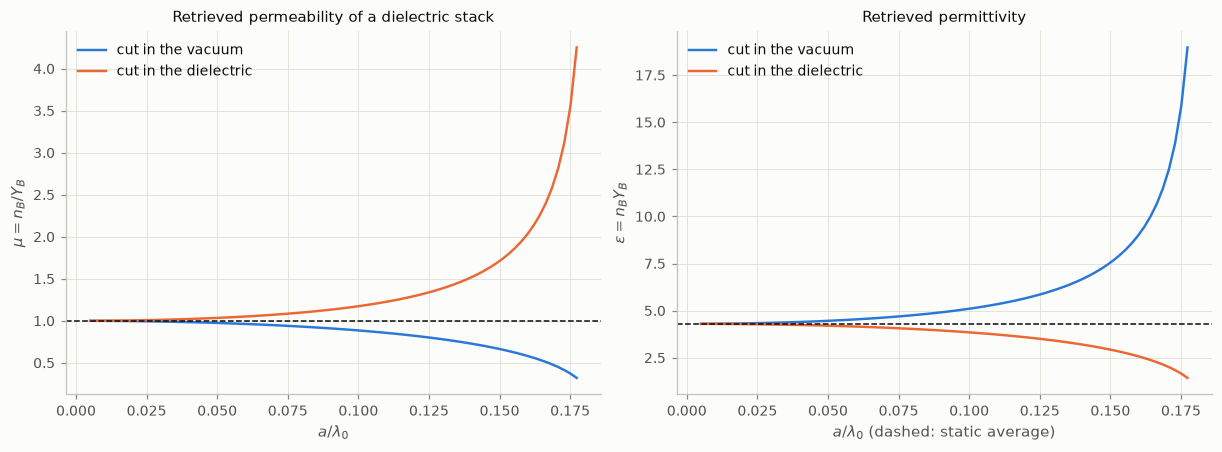

PASS  5 cells cut in the vacuum: exact (r, t) equal the homogeneous slab (n_B, Y_B): got 2.81851e-15, target 0, |diff| 2.82e-15 <= 1e-12
PASS  5 cells cut in the dielectric: exact (r, t) equal the homogeneous slab (n_B, Y_B): got 2.11789e-15, target 0, |diff| 2.12e-15 <= 1e-12
PASS  the Bloch index is the same for both cuts (max difference): got 5.41789e-14, target 0, |diff| 5.42e-14 <= 1e-12
(mu - 1) / (k0 a)^2 at the lowest frequency: -0.2503 (cut in the vacuum), +0.3275 (cut in the dielectric)
range of the retrieved mu over the first band: 0.320 to 0.9998 (cut in the vacuum), 1.0003 to 4.252 (cut in the dielectric)


In [9]:
def layer_matrix(k0, d, eps):
    n = np.sqrt(complex(eps)); ph = n * k0 * d
    return np.array([[np.cos(ph), -1j * np.sin(ph) / n], [-1j * n * np.sin(ph), np.cos(ph)]])


def cell_matrix(k0, cut, eps_a=12.0, d_a=0.3):
    if cut == "vacuum":
        return layer_matrix(k0, (1 - d_a) / 2, 1) @ layer_matrix(k0, d_a, eps_a) @ layer_matrix(k0, (1 - d_a) / 2, 1)
    return layer_matrix(k0, d_a / 2, eps_a) @ layer_matrix(k0, 1 - d_a, 1) @ layer_matrix(k0, d_a / 2, eps_a)


def bloch_parameters(k0, cut):
    (A, B), (C, D) = cell_matrix(k0, cut)
    q = np.arccos(A.real)                                # lossless pass band, symmetric cell: A = D real
    Y = np.sqrt(C / B)
    return q / k0, (Y if Y.real > 0 else -Y)


f_scan = np.linspace(0.005, 0.4, 4000)                  # the first band ends where |cos(q a)| reaches one
f_edge = f_scan[np.argmax(np.abs([cell_matrix(2 * np.pi * f, "vacuum")[0, 0].real for f in f_scan]) > 1)]
print(f"first band edge of the stack at a/lambda = {f_edge:.4f}")
fs = np.linspace(0.005, 0.97 * f_edge, 80)
par = {cut: np.array([bloch_parameters(2 * np.pi * f, cut) for f in fs]) for cut in ("vacuum", "dielectric")}
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for cut, col in (("vacuum", CAT[0]), ("dielectric", CAT[1])):
    n, Y = par[cut][:, 0].real, par[cut][:, 1].real
    axs[0].plot(fs, n / Y, color=col, label=f"cut in the {cut}")
    axs[1].plot(fs, n * Y, color=col, label=f"cut in the {cut}")
axs[0].axhline(1.0, color=INK, ls="--", lw=1)
axs[1].axhline(1 + 0.3 * 11, color=INK, ls="--", lw=1)
axs[0].set(xlabel=r"$a/\lambda_0$", ylabel=r"$\mu=n_B/Y_B$", title="Retrieved permeability of a dielectric stack"); axs[0].legend()
axs[1].set(xlabel=r"$a/\lambda_0$ (dashed: static average)", ylabel=r"$\varepsilon=n_BY_B$", title="Retrieved permittivity"); axs[1].legend()
plt.show()

k0 = 2 * np.pi * 0.7 * f_edge
for cut in ("vacuum", "dielectric"):
    nB, YB = bloch_parameters(k0, cut)
    Mn = np.linalg.matrix_power(cell_matrix(k0, cut), 5)
    (A, B), (C, D) = Mn
    r_exact, t_exact = (A + B - C - D) / (A + B + C + D), 2 / (A + B + C + D)
    r_h, t_h = sharp_slab(k0, 5.0, nB, YB)
    check(f"5 cells cut in the {cut}: exact (r, t) equal the homogeneous slab (n_B, Y_B)", abs(r_exact - r_h) + abs(t_exact - t_h), 1e-12)
check("the Bloch index is the same for both cuts (max difference)", np.abs(par["vacuum"][:, 0] - par["dielectric"][:, 0]).max(), 1e-12)
c_vac = ((par["vacuum"][:, 0] / par["vacuum"][:, 1]).real - 1) / (2 * np.pi * fs) ** 2
c_die = ((par["dielectric"][:, 0] / par["dielectric"][:, 1]).real - 1) / (2 * np.pi * fs) ** 2
print(f"(mu - 1) / (k0 a)^2 at the lowest frequency: {c_vac[0]:+.4f} (cut in the vacuum), {c_die[0]:+.4f} (cut in the dielectric)")
mu_vac, mu_die = (par["vacuum"][:, 0] / par["vacuum"][:, 1]).real, (par["dielectric"][:, 0] / par["dielectric"][:, 1]).real
print(f"range of the retrieved mu over the first band: {mu_vac.min():.3f} to {mu_vac.max():.4f} (cut in the vacuum), {mu_die.min():.4f} to {mu_die.max():.3f} (cut in the dielectric)")
assert mu_vac.max() < 1 < mu_die.min(), "the two cuts lie on opposite sides of one"

The index is one curve. The retrieved permeability is two: below one when the stack ends in the middle of the vacuum layer, above one when it ends in the middle of the dielectric, with deviations proportional to $(k_0a)^2$ at low frequency and of tens of percent before the band edge. Nothing in this structure is magnetic. In circuit terms the dielectric layer is a shunt capacitance and the cell is a T section in one cut and a $\Pi$ section in the other, whose image impedances are $Z_0\cos(qa/2)$ and $Z_0/\cos(qa/2)$ in the lumped limit. The Bloch admittance is a property of the termination, as Simovski stressed, and the "diamagnetism" of the first cut is the simplest instance of the artifacts that retrievals attribute to $\mu$.

Both examples say the same thing in different words. The bulk response, in whatever bookkeeping, fixes the waves inside. What happens at a boundary depends on how the response is terminated there, which the bulk tensor does not encode.

## Summary

- **Equivalence.** Local $\varepsilon$, $\mu$ and magnetoelectric couplings map exactly onto one tensor $\varepsilon_{\rm LL}(\omega,\mathbf k)$; the permeability is the term $K^{\mathsf T}(1-\mu^{-1})K/k_0^2$. The two descriptions respond identically to any source (checked off shell on random media).
- **Bulk waves fix $n$ only.** All splits of $n^2$ coincide on the dispersion curve. The split needs off-shell data or an interface.
- **Symmetry.** With $\mathbf E$ along the axis of a two-dimensional lattice every second-order term is a permeability. With $\mathbf E$ in the plane of a square lattice there are three, $\tau$ (magnetic), $\lambda$ (longitudinal) and $\delta$ (anisotropic, not a permeability and seen by transverse waves as an apparent $\mu$ that varies as $\cos4\varphi$).
- **Criterion and multipoles.** A magnetization is meaningful when the loop coefficient dominates the other second-order terms (Landau and Lifshitz). The magnetic dipole of a cell is one of four contributions at second order, and for a weak rod polarized along its axis the sum is zero.
- **Interfaces.** The same symbol with different operator orderings, or the same stack with different cuts, reflects differently.

## Questions for the rod lattice

1. How large is the second-order term of $\varepsilon(\omega,\mathbf k)$ near a Mie resonance of the rods, is it the isotropic transverse one, and by how much does it satisfy the Landau-Lifshitz criterion? (notebook 03)
2. How far in $k$ does the second-order description hold, compared with the Bloch wavenumber at that frequency? (notebooks 02 and 03)
3. Does the permeability read off the bulk tensor give the reflection of a slab? (notebook 04)

## Caveats and open ends

- Section 3 counts coefficients for reciprocal media and a real symmetry group; magnetic point groups and nonreciprocal media are not covered.
- Section 4 is a statement about one polarization and the Born limit. The general decomposition of the second-order term into multipole responses, and its dependence on the choice of origin, is not worked out here.
- Section 5.1 shows that orderings differ, not which one a given structure realizes. Hermitian surface terms beyond the three orderings (a surface polarizability) are possible and are not explored.

## References

- L. D. Landau, E. M. Lifshitz and L. P. Pitaevskii, *Electrodynamics of Continuous Media*, 2nd ed. (Pergamon, 1984): section 79 for the argument that the permeability loses its meaning at high frequency (page 251 of the 1960 edition), sections 103 to 106 for spatial dispersion.
- R. Merlin, Proc. Natl. Acad. Sci. USA 106, 1693 (2009), "Metamaterials and the Landau-Lifshitz permeability argument: Large permittivity begets high-frequency magnetism".
- V. M. Agranovich and Yu. N. Gartstein, Metamaterials 3, 1 (2009), on the Landau-Lifshitz approach to the permeability of metamaterials; Phys. Usp. 49, 1029 (2006), on spatial dispersion and negative refraction.
- V. M. Agranovich and V. L. Ginzburg, *Crystal Optics with Spatial Dispersion, and Excitons* (Springer, 1984).
- J. Skaar, H. O. Hågenvik and C. A. Dirdal, Phys. Rev. B 99, 064407 (2019), four definitions of the permeability of a periodic metamaterial; C. A. Dirdal, H. O. Hågenvik, H. A. Haave and J. Skaar, IEEE Trans. Antennas Propag. 66, 6403 (2018), on multipoles beyond the quadrupole at second order.
- M. G. Silveirinha, Phys. Rev. B 75, 115104 (2007), nonlocal homogenization with a source.
- A. Alù, Phys. Rev. B 84, 075153 (2011), first-principles homogenization of periodic arrays.
- C. R. Simovski, Metamaterials 1, 62 (2007), Bloch material parameters; C. R. Simovski and S. A. Tretyakov, Phys. Rev. B 75, 195111 (2007).
- R. E. Raab and O. L. de Lange, *Multipole Theory in Electromagnetism* (Oxford, 2005).
- H. A. Lorentz (1878) on the optical anisotropy of cubic crystals; J. Pastrnak and K. Vedam, Phys. Rev. B 3, 2567 (1971); J. H. Burnett, Z. H. Levine and E. L. Shirley, Phys. Rev. B 64, 241102 (2001).